# 02 · Baseline 1: TF-IDF + logistic regression

Before using a 4-billion-parameter model I need a cheap, strong baseline. Without one there is no way to tell whether the LLM is worth its cost.

**Features.** Darija has no standard spelling. The same word can appear as `bzaf`, `bezzaf`, `bzzaaaf` or `بزاف`. Word n-grams treat each of these as a separate feature, but **character n-grams** share most of their pieces. I combine both:
- character n-grams (2–5, within word boundaries), which are robust to spelling variation and work for both scripts,
- word uni- and bi-grams, which capture whole expressions like `ربي يحفظك`.

Before vectorising, the text goes through `normalize_for_ngrams`: lower-casing, merging alef/ya/ta-marbuta variants, removing diacritics and tatweel, and squeezing letter repeats (`هههههه` → `هه`).

**Model.** Multinomial logistic regression. The regularisation strength `C` and class weighting are picked on the **validation** set; the test set is used once at the end.

In [1]:
import sys
sys.path.insert(0, "../src")

import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline, make_union

from darija_sentiment.config import LABELS
from darija_sentiment.data import load_splits, normalize_for_ngrams
from darija_sentiment.metrics import (
    bootstrap_ci, evaluate, evaluate_by_script, macro_f1, plot_confusion, save_figure, save_metrics, save_predictions,
)

splits = load_splits()
train, val, test = splits["train"], splits["val"], splits["test"]
print({k: len(v) for k, v in splits.items()})

{'train': 39968, 'val': 4996, 'test': 4996}


In [2]:
def make_vectorizer():
    return make_union(
        TfidfVectorizer(preprocessor=normalize_for_ngrams, analyzer="char_wb", ngram_range=(2, 5),
                        min_df=2, sublinear_tf=True, max_features=300_000),
        TfidfVectorizer(preprocessor=normalize_for_ngrams, analyzer="word", ngram_range=(1, 2),
                        token_pattern=r"(?u)\b\w+\b", min_df=2, sublinear_tf=True),
    )

vectorizer = make_vectorizer()
X_train = vectorizer.fit_transform(train["text"])
X_val = vectorizer.transform(val["text"])
print("feature matrix:", X_train.shape)

feature matrix: (39968, 245325)


## Hyper-parameter search on the validation set

In [3]:
results = []
for class_weight in [None, "balanced"]:
    for C in [0.125, 0.25, 0.5, 1, 2, 4, 8]:
        clf = LogisticRegression(C=C, class_weight=class_weight, max_iter=3000)
        clf.fit(X_train, train["label"])
        results.append({"C": C, "class_weight": str(class_weight), "val_macro_f1": macro_f1(val["label"], clf.predict(X_val))})

search = pd.DataFrame(results).pivot(index="C", columns="class_weight", values="val_macro_f1")
search.round(4)

class_weight,None,balanced
C,,
0.125,0.7423,0.7560
0.250,0.7573,0.7610
0.500,0.7688,0.7643
1.000,0.7672,0.7631
2.000,0.7636,0.7582
4.000,0.7597,0.7558
8.000,0.7533,0.7542


In [4]:
best = max(results, key=lambda r: r["val_macro_f1"])
best_C, best_cw = best["C"], None if best["class_weight"] == "None" else best["class_weight"]
print("best:", best)

best: {'C': 0.5, 'class_weight': 'None', 'val_macro_f1': 0.768791423919546}


## Final model and test evaluation

The final pipeline is refit on the training set only, so the validation set stays unused for a fair comparison with the LoRA model, which also never trains on it.

In [5]:
pipeline = make_pipeline(make_vectorizer(), LogisticRegression(C=best_C, class_weight=best_cw, max_iter=3000))
start = time.time()
pipeline.fit(train["text"], train["label"])
print(f"training time: {time.time() - start:.1f} s (CPU)")

start = time.time()
proba = pipeline.predict_proba(test["text"])
print(f"inference on {len(test):,} comments: {time.time() - start:.2f} s")

test_pred = test.assign(pred=proba.argmax(1), p_negative=proba[:, 0], p_neutral=proba[:, 1], p_positive=proba[:, 2])
by_script = evaluate_by_script(test_pred)
by_script.round(4)

training time: 13.9 s (CPU)


inference on 4,996 comments: 0.86 s


,macro_f1,accuracy,f1_negative,f1_neutral,f1_positive,n
subset,,,,,,
all,0.7617,0.7956,0.7972,0.6106,0.8773,4996
arabic,0.7656,0.7956,0.8029,0.6186,0.8752,4306
latin,0.7147,0.7991,0.7559,0.4970,0.8914,632
mixed,0.7965,0.8200,0.7059,0.8000,0.8837,50


In [6]:
ci = bootstrap_ci(test_pred["label"], test_pred["pred"])
print(f"test macro-F1 = {by_script.loc['all', 'macro_f1']:.4f}  (95% bootstrap CI {ci[0]:.4f}–{ci[1]:.4f})")

save_predictions(test_pred, "tfidf_logreg")
save_metrics({
    "system": "TF-IDF + logistic regression",
    "hyperparameters": {"C": best_C, "class_weight": best_cw},
    "val_macro_f1": best["val_macro_f1"],
    "test": by_script.to_dict(orient="index"),
    "test_macro_f1_ci95": ci,
}, "tfidf_logreg")

test macro-F1 = 0.7617  (95% bootstrap CI 0.7494–0.7742)


**A strong baseline: 0.762 macro-F1 (95% CI 0.749–0.774)**, from 15 seconds of CPU training and under a second of inference for the whole test set. Any LLM has to beat this by a clear margin to justify its cost.

The weak spot is the **neutral** class (F1 0.61), and it is worst for Latin-script comments (F1 0.50). Arabizi spelling is the least standardised and the comments are the shortest, so a bag of n-grams has the least to go on there.

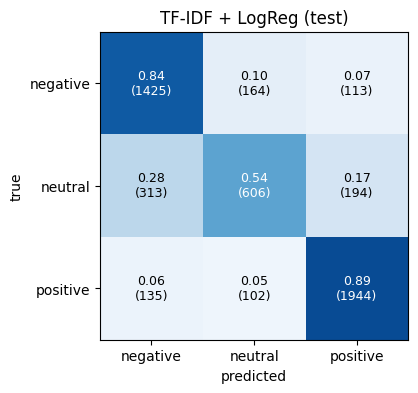

In [7]:
fig, ax = plt.subplots(figsize=(4.4, 4))
plot_confusion(test_pred["label"], test_pred["pred"], "TF-IDF + LogReg (test)", ax=ax)
save_figure(fig, "confusion_tfidf_logreg")

## What does the model rely on?

A linear model can be inspected directly. Below are the n-grams with the largest positive weights for each class:

In [8]:
vec, clf = pipeline[0], pipeline[-1]
names = np.concatenate([t.get_feature_names_out() for _, t in vec.transformer_list])
kinds = np.concatenate([[k] * len(t.get_feature_names_out()) for k, t in vec.transformer_list])
top = {}
for i, label in enumerate(LABELS):
    order = np.argsort(clf.coef_[i])[::-1]
    word_feats = [names[j] for j in order if kinds[j].startswith("tfidfvectorizer-2")][:15]
    top[label] = word_feats
pd.DataFrame(top)

,negative,neutral,positive
0,ya,هل,تحيه
1,الله لا,شكون,ربي
2,العار,سلام,روعه
3,عيب,svp,شكرا
4,يا,عندي,الصحه
5,بلاد,وين,الله
6,فرنسا,9,bravo
7,بفف,ديرنا,فوور
8,كلاب,ممكن,اروع
9,تعيي,اذا,رائع


The word features read like a lexicon of Algerian YouTube comment sections:

- **negative** is driven by insults and shame words: `كلاب` (*dogs*), `خونه` (*traitors*), `العار` (*shame*), `عيب` (*disgraceful*), `رخيس` (*cheap*), `الله لا` (the start of curses like *"may God not…"*), and also `فرنسا` (*France*).
- **neutral** is mostly **questions and requests**: `هل`, `شكون` (*who*), `وين`/`اين` (*where*), `لماذا` (*why*), `ممكن` (*could you*), `من فضلك` / `svp` (*please*).
- **positive** is praise and thanks in three languages: `روعه`, `رائع`, `اروع` (*amazing*), `شكرا`/`merci`, `bravo`, `vive`, `فور` (from French *fort*, "awesome").

This shows what the baseline can and cannot do. It learns surface cues well, so a question becomes neutral and an insult word becomes negative. It has no way to handle negation, sarcasm, or a positive word used in a negative context.